<h1>Analysis of the Mental Rotation 2D experiment</h1> 

Volunteers took the experiment at <https://github.com/chrplr/goxpyriment/tree/main/examples/Mental-Rotation-2D>

The individual results files are in the subfolder `./data`

In [1]:
# run this only if you are executing within colab.research.google.com
! git clone https://github.com/chrplr/mental-rotation-analysis
! cd mental-rotation-analysis

Cloning into 'mental-rotation-analysis'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 44 (delta 22), reused 42 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 5.09 MiB | 27.30 MiB/s, done.
Resolving deltas: 100% (22/22), done.


In [2]:
# you may need to install those packages
# ! pip install numpy pandas seaborn
# ! uv pip install numpy pandas seaborn

In [3]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Importing data into a single pandas.DataFrame

In [4]:
folder = Path("data")
files = list(folder.glob("*.csv"))
print(len(files))
files

16


[PosixPath('data/res2.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260924-064330.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260924-095059.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260927-181811.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-020_date-20260926-162037.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260924-095218.csv'),
 PosixPath('data/res.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-000_date-20260924-094820.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-000_date-20260924-095043.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260927-161502.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-000_date-20260924-095219.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-1612_date-20260930-140849.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260924-101256.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260924-095036.csv'),
 PosixPath('data/Mental-Rotation-2D_sub-001_date-20260926-211937.csv'),
 Posix

In [5]:
data = pd.concat(
    {f.name: pd.read_csv(f) for f in files}, names=["file_name"]
).reset_index(level=0)
data.head()

,file_name,subject_id,trial_idx,angle,condition,response,is_correct,rt
0,res2.csv,1,1,80,same,same,True,2121
1,res2.csv,1,2,80,same,same,True,2203
2,res2.csv,1,3,160,mirrored,mirrored,True,4005
3,res2.csv,1,4,0,mirrored,mirrored,True,2939
4,res2.csv,1,5,0,same,same,True,1894


## Data inspection and cleaning

### number of datapoints in each file

In [6]:
data.groupby(["file_name"]).rt.size()

file_name
Mental-Rotation-2D_sub-000_date-20260924-094820.csv     40
Mental-Rotation-2D_sub-000_date-20260924-095043.csv     40
Mental-Rotation-2D_sub-000_date-20260924-095219.csv     40
Mental-Rotation-2D_sub-001_date-20260924-064330.csv     13
Mental-Rotation-2D_sub-001_date-20260924-095036.csv     40
Mental-Rotation-2D_sub-001_date-20260924-095059.csv     40
Mental-Rotation-2D_sub-001_date-20260924-095218.csv     40
Mental-Rotation-2D_sub-001_date-20260924-095332.csv     40
Mental-Rotation-2D_sub-001_date-20260924-101256.csv     40
Mental-Rotation-2D_sub-001_date-20260926-211937.csv     40
Mental-Rotation-2D_sub-001_date-20260927-161502.csv     40
Mental-Rotation-2D_sub-001_date-20260927-181811.csv     40
Mental-Rotation-2D_sub-020_date-20260926-162037.csv     40
Mental-Rotation-2D_sub-1612_date-20260930-140849.csv    40
res.csv                                                 40
res2.csv                                                40
Name: rt, dtype: int64

Let's remove the file with less than 40 datapoints

In [7]:
files_ok = [f for f in files if f.name != "Mental-Rotation-2D_sub-001_date-20260924-064330.csv"]

In [8]:

data = pd.concat(
    {f.name: pd.read_csv(f) for f in files_ok}, names=["file_name"]
).reset_index(level=0)
data.head()

,file_name,subject_id,trial_idx,angle,condition,response,is_correct,rt
0,res2.csv,1,1,80,same,same,True,2121
1,res2.csv,1,2,80,same,same,True,2203
2,res2.csv,1,3,160,mirrored,mirrored,True,4005
3,res2.csv,1,4,0,mirrored,mirrored,True,2939
4,res2.csv,1,5,0,same,same,True,1894


... and recreate the dataframe with the new list of files

## Associating a unique subject_id to each file_name

In [9]:
unique_files = data['file_name'].unique()
file_map = {name: (i + 1) for i, name in enumerate(unique_files)}

data['subject_id'] = data['file_name'].map(file_map).astype('category')
data

,file_name,subject_id,trial_idx,angle,condition,response,is_correct,rt
0,res2.csv,1,1,80,same,same,True,2121
1,res2.csv,1,2,80,same,same,True,2203
2,res2.csv,1,3,160,mirrored,mirrored,True,4005
3,res2.csv,1,4,0,mirrored,mirrored,True,2939
4,res2.csv,1,5,0,same,same,True,1894
...,...,...,...,...,...,...,...,...
35,Mental-Rotation-2D_sub-001_date-20260924-09533...,15,36,40,same,same,True,578
36,Mental-Rotation-2D_sub-001_date-20260924-09533...,15,37,160,same,same,True,2912
37,Mental-Rotation-2D_sub-001_date-20260924-09533...,15,38,160,mirrored,mirrored,True,756
38,Mental-Rotation-2D_sub-001_date-20260924-09533...,15,39,80,mirrored,mirrored,True,724


In [10]:
data.to_csv("mental-rotation-2D-all-data.csv")

# Descriptive analysis of Error rates

In [11]:
data.groupby("subject_id").is_correct.mean()*40

subject_id
1     39.0
2     39.0
3     40.0
4     40.0
5     37.0
6     35.0
7     39.0
8     38.0
9     40.0
10    38.0
11    40.0
12    39.0
13    39.0
14    40.0
15    39.0
Name: is_correct, dtype: float64

Let's inspect the errors

In [12]:
data[data.is_correct==False]

,file_name,subject_id,trial_idx,angle,condition,response,is_correct,rt
22,res2.csv,1,23,160,same,mirrored,False,1428
29,Mental-Rotation-2D_sub-001_date-20260924-09505...,2,30,0,mirrored,same,False,639
4,Mental-Rotation-2D_sub-001_date-20260924-09521...,5,5,40,mirrored,same,False,1301
5,Mental-Rotation-2D_sub-001_date-20260924-09521...,5,6,80,same,mirrored,False,0
34,Mental-Rotation-2D_sub-001_date-20260924-09521...,5,35,80,same,mirrored,False,659
3,res.csv,6,4,160,mirrored,same,False,1963
6,res.csv,6,7,120,same,mirrored,False,1442
15,res.csv,6,16,80,mirrored,same,False,1412
18,res.csv,6,19,120,mirrored,same,False,725
37,res.csv,6,38,160,same,mirrored,False,1340


# Analysis of Reaction times

First, we inspect their distribution with an histogram

<Axes: xlabel='rt', ylabel='Count'>

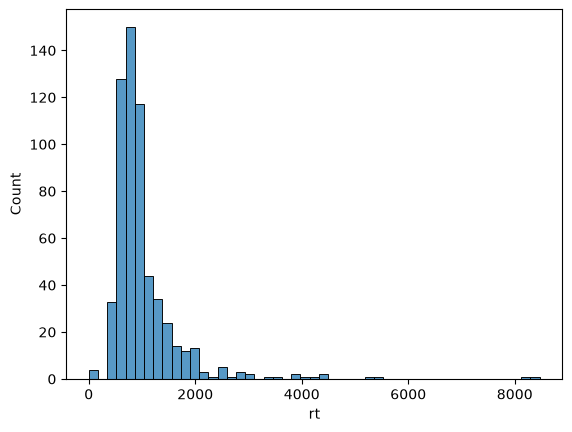

In [13]:
sns.histplot(data.rt)

Another (better?) way to look at distributions: boxplot

<Axes: ylabel='rt'>

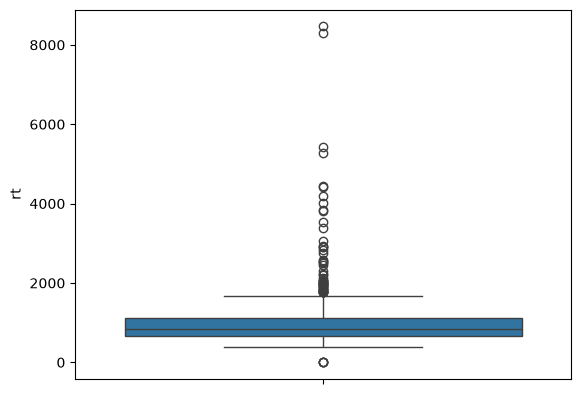

In [14]:
sns.boxplot(data.rt)

<Axes: ylabel='rt'>

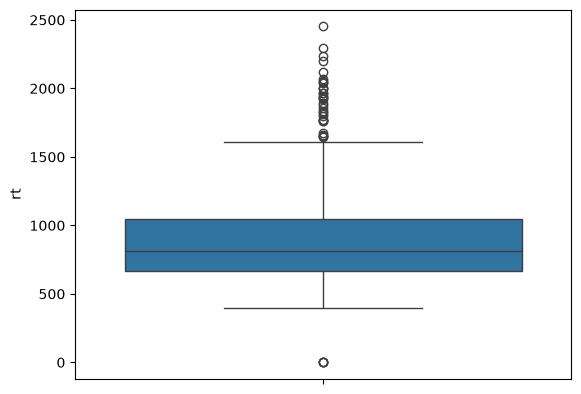

In [15]:
#zooming
sns.boxplot(data.loc[data.rt < 2500].rt)

## individual differences 

<Axes: xlabel='rt'>

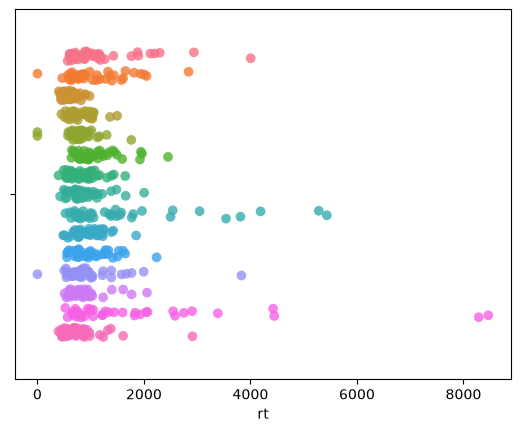

In [16]:
sns.stripplot(
    x=data.rt,
    hue=data.subject_id,
    jitter=0.2,  # Adds slight vertical spread so overlapping points remain visible
    size=7,
    alpha=0.8,
    dodge=True,
    legend=False
)

## Removing outliers

In [17]:
data_clean = data.query("rt>150 and is_correct==True ")   

In [18]:
print(len(data))   # number of original data points
len(data) - len(data_clean)   # number of rejected data points

600


21

In [19]:
medrt = data_clean.groupby("subject_id").rt.median()
medrt

subject_id
1      936.0
2      885.0
3      591.5
4      734.5
5      803.0
6      955.0
7      801.0
8      786.0
9     1041.5
10     906.0
11     971.5
12     829.5
13     819.0
14    1131.5
15     692.0
Name: rt, dtype: float64

<Axes: xlabel='rt'>

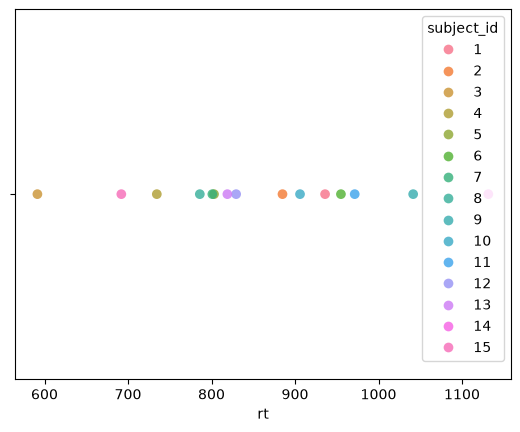

In [20]:
sns.stripplot(
    x=medrt,
    hue=medrt.index,
    jitter=0,
    size=7,
    alpha=0.8,
)

# Effects of angle and condition (same vs mirror)

In [21]:
rts2 = data_clean.groupby(["subject_id", "condition", "angle"]).rt.median().reset_index()
rts2

,subject_id,condition,angle,rt
0,1,mirrored,0,683.0
1,1,mirrored,40,746.0
2,1,mirrored,80,810.5
3,1,mirrored,120,1000.0
4,1,mirrored,160,1394.0
...,...,...,...,...
145,15,same,0,462.5
146,15,same,40,634.5
147,15,same,80,687.0
148,15,same,120,864.0


In [22]:
rts3 = data_clean.groupby(["condition", "angle"]).rt.median().reset_index()
rts3

,condition,angle,rt
0,mirrored,0,744.0
1,mirrored,40,807.5
2,mirrored,80,857.0
3,mirrored,120,938.0
4,mirrored,160,1111.0
5,same,0,623.0
6,same,40,688.0
7,same,80,776.5
8,same,120,924.5
9,same,160,1057.0


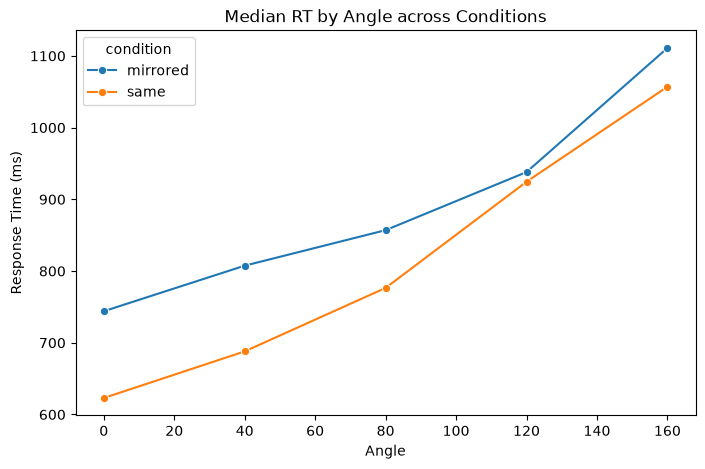

In [23]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=rts3,
    x="angle",
    y="rt",
    hue="condition",
    marker="o",  
)

plt.xlabel("Angle")
plt.ylabel("Response Time (ms)")
plt.title("Median RT by Angle across Conditions")
plt.show()

# Inferential analysis

**Are the differences statistically significant? That is, what is the probability that there are due to chance fluctuations?** 

If we find that the probability is small, then we will reject the "null" hypothesis). The approach is called "Hypothesis testing". 

<Figure size 800x500 with 0 Axes>

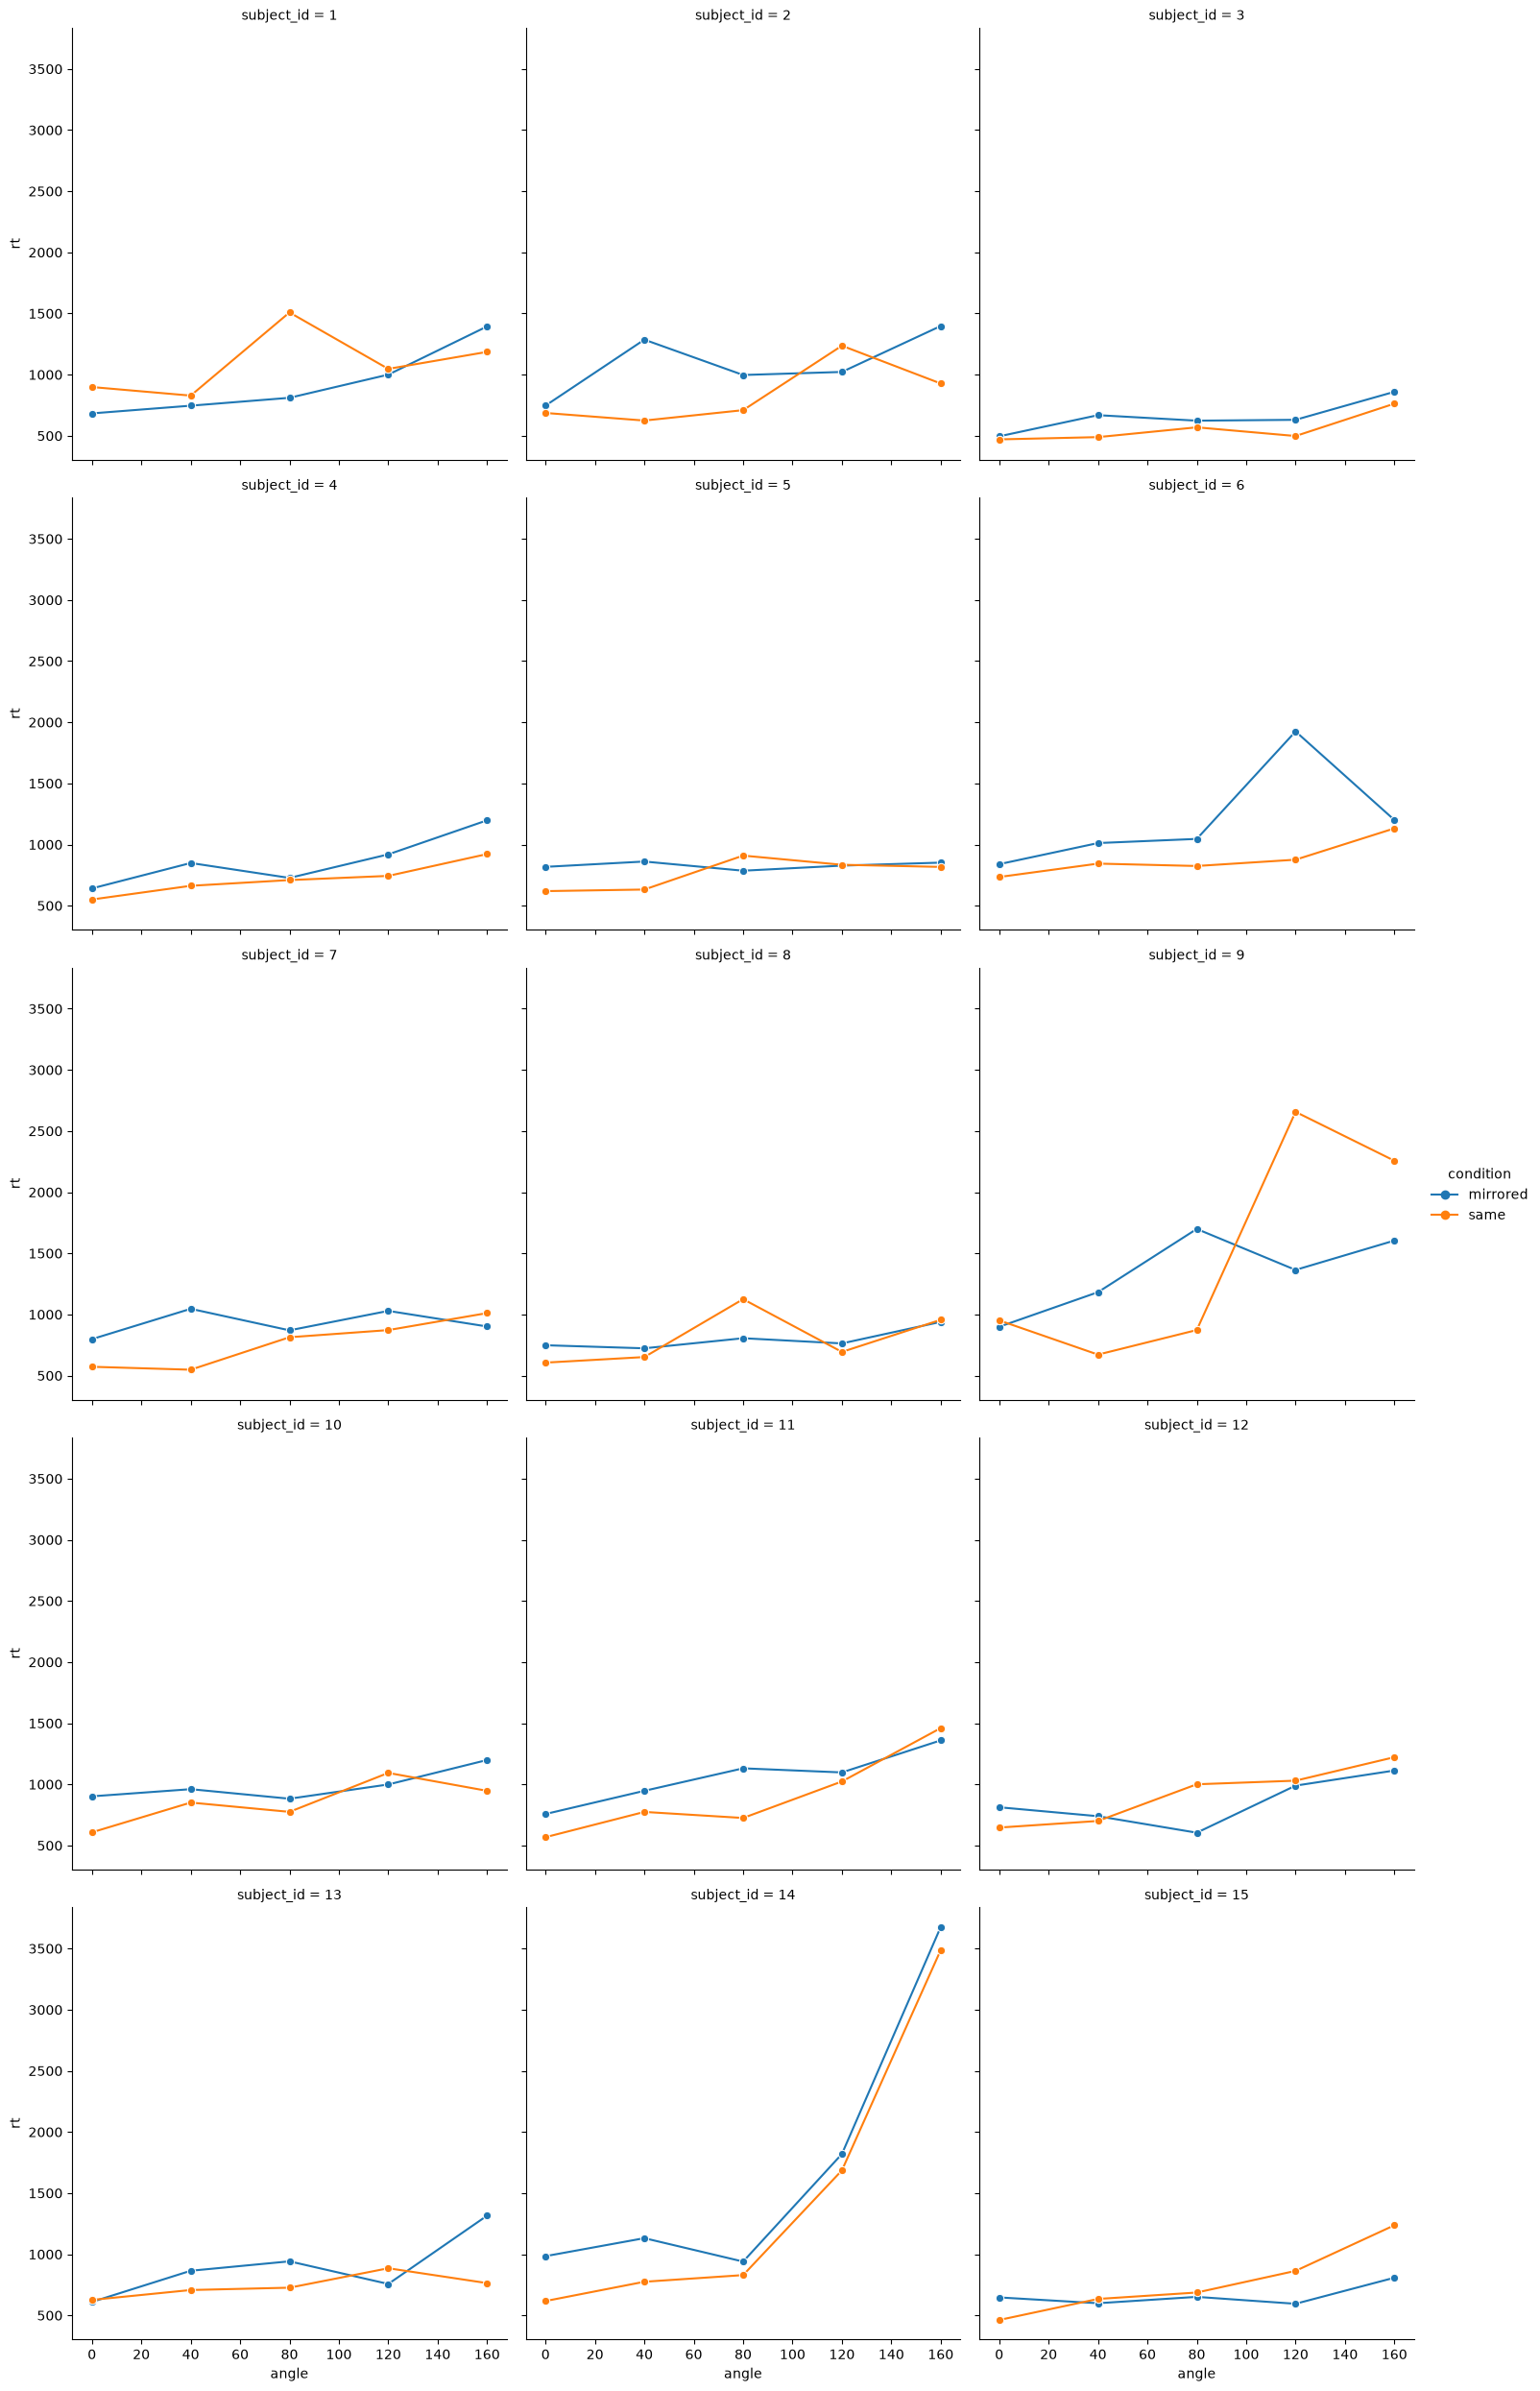

In [24]:
plt.figure(figsize=(8, 5))

sns.relplot(
    data=rts2,
    x="angle",
    y="rt",
    hue="condition",
    col="subject_id",  # Creates a subplot per subject
    col_wrap=3,  # Wraps after 3 plots per row
    kind="line",
    marker="o",
)



Let's forget the distinction between mirror & same

<Axes: xlabel='angle', ylabel='rt'>

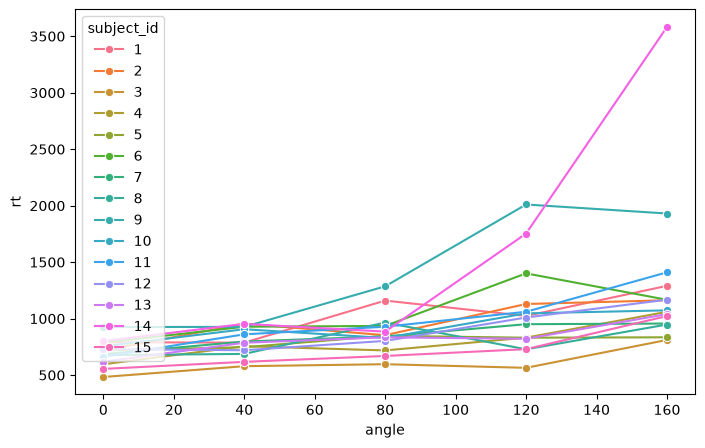

In [25]:
# indivual results superposed
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=rts2,
    x="angle",
    y="rt",
    hue="subject_id",  # Creates a subplot per subject
    marker="o",
    errorbar=None
)

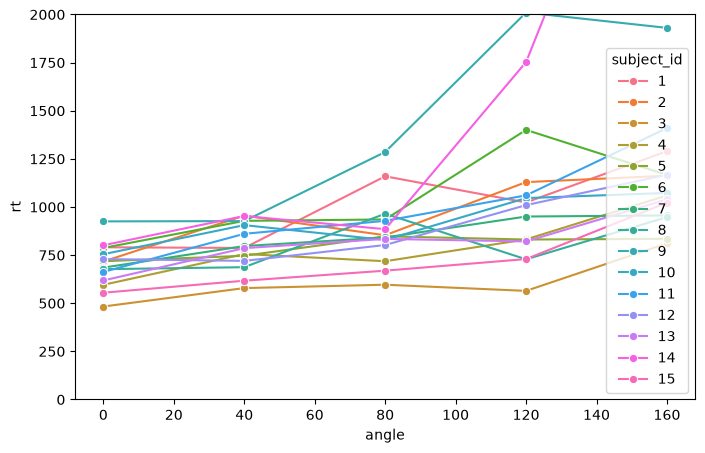

In [26]:
# indivual results superposed
plt.figure(figsize=(8, 5))

ax = sns.lineplot(
    data=rts2,
    x="angle",
    y="rt",
    hue="subject_id",  # Creates a subplot per subject
    marker="o",
    errorbar=None
)

# Set lower and upper y-axis limits
ax.set_ylim(0, 2000)

plt.show()

Note the two different questions:
* is there an effect of angle in the human population overall?
* is there an effect of angle for every human being?

We ask the first one: if we can characterize each human by a an effect of angle (e.g. the slope), then, is the distribution of this effect centered on zero or not?

<Axes: xlabel='angle', ylabel='rt'>

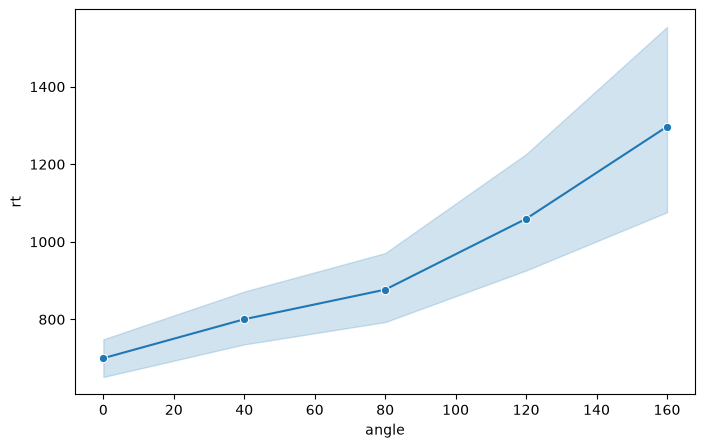

In [27]:
# group result

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=rts2,
    x="angle",
    y="rt",
    marker="o",
    errorbar="ci"  # <- asks to draw 95% confidence intervals 
)

Let's compute p-values for the differences between angles conditions.

We need a vector of reations times (1 per participant) for each angle (0, 40, 80, 120, 160). 

In [28]:
angles_rt = rts2.groupby(["angle", "subject_id"]).rt.mean().reset_index()
angles_rt

,angle,subject_id,rt
0,0,1,790.75
1,0,2,716.75
2,0,3,483.00
3,0,4,595.75
4,0,5,718.25
...,...,...,...
70,160,11,1409.75
71,160,12,1167.50
72,160,13,1039.75
73,160,14,3581.75


In [29]:
rt0 = angles_rt.query("angle==0").rt.to_numpy()
rt40 = angles_rt.query("angle==40").rt.to_numpy()
rt80 = angles_rt.query("angle==80").rt.to_numpy()
rt120 = angles_rt.query("angle==120").rt.to_numpy()
rt160 = angles_rt.query("angle==160").rt.to_numpy()

In [30]:
rt40-rt0

array([ -3.5 , 238.5 ,  95.75, 160.  ,  28.25, 141.  , 112.  ,  10.25,
         1.5 , 151.  , 198.  ,  -9.5 , 168.  , 152.25,  62.25])

<Axes: >

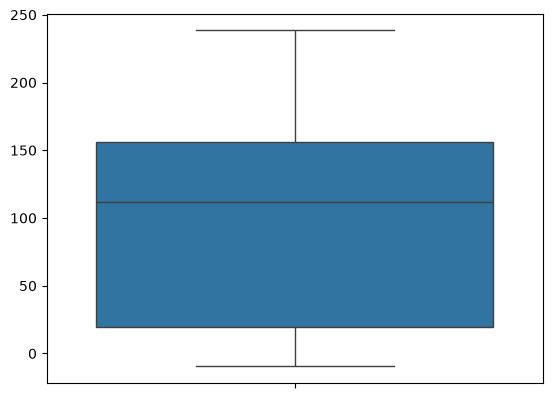

In [31]:
sns.boxplot(rt40-rt0)

Let's compute the p-values using a permutation test (see <https://en.wikipedia.org/wiki/Permutation_test>)

Example of a permutation test to compare 2 groups

Suppose we have height measures for two groups of 4 french & four germans

In [32]:
germans = np.array([182, 171, 178, 189])
frenchies = np.array([168, 176, 157, 175])

Idea: if there is no difference between French and German populations, French & GErman are interchangeable. In other words, we can arbitrarily sort participants in the two groups.

Let do that, many times, and compute the height difference between the groups obtained each time. 

Then draw the histogram of these differences, and locate the rank of the observed difference in the real groups.

In [33]:
def two_groups_permutation_test(group1, group2, npermutations=10000):
    n1 = len(group1)
    n2 = len(group2)
    obs_diff = np.mean(group1) - np.mean(group2)
    print(f"Observed difference: {obs_diff}")
    all = np.hstack((group1, group2))
    diffs = []
    for _ in range(npermutations):
        random.shuffle(all)
        list1 = all[:n1] 
        list2 = all[n1:] 
        diffs.append(np.mean(list1) - np.mean(list2))
    sns.histplot(diffs)
    return float(np.mean(obs_diff >= diffs)) 
    

Observed difference: 11.0


0.9586

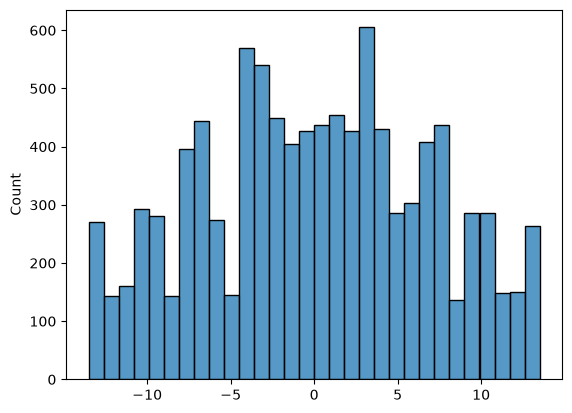

In [34]:

two_groups_permutation_test(germans, frenchies)


In [35]:
def my_permutation_test(sample, npermutations=10000):
    """ test if sample mean is significantly above 0 (one-tail test) """
    obs_mean = sample.mean()
    p = len(sample)
    h0_dist = np.array([1/ p * (sample @ np.random.choice([1, -1], size=p)) for _ in range(npermutations)])
    return float(np.mean(h0_dist >= obs_mean))  # pvalue
        

In [36]:
print((rt40-rt0).mean())
my_permutation_test(rt40-rt0)

100.38333333333334


0.0003

In [37]:
my_permutation_test(rt80-rt40)

0.0374

In [38]:
my_permutation_test(rt120-rt80)

0.013

In [39]:
my_permutation_test(rt160-rt120)

0.0061

## using scipy

### permutation test

In [40]:
from scipy.stats import permutation_test

def statistic(x, axis):
    return np.mean(x, axis=axis)

data = (rt40-rt0,)

res = permutation_test(data, statistic, permutation_type='samples', n_resamples=10000)

print(f"Observed Statistic: {res.statistic}")
print(f"p-value: {res.pvalue}")
print(f"Null Distribution: {res.null_distribution}")

Observed Statistic: 100.38333333333334
p-value: 0.0005999400059994001
Null Distribution: [  7.55        -7.55        13.55       ... -22.01666667 -28.61666667
  56.08333333]


### Student t-test

See <https://en.wikipedia.org/wiki/Student%27s_t-test>

In [41]:
from scipy import stats

# computing the t value "à la mano"
m = (rt40-rt0).mean()
s = (rt40-rt0).std()
n = len(rt40-rt0)
t = m/s*np.sqrt(n-1)
print(m,s,n,t)


t_stat, p_val = stats.ttest_1samp(rt40-rt0, popmean=0)

print(f"t-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")

100.38333333333334 77.98081316722866 15 4.816569940995472
t-statistic: 4.8166, p-value: 0.0003


# Estimation of a mean

In [47]:
import statsmodels.stats.api as sms
d = sms.DescrStatsW(rt40-rt0)
d.tconfint_mean()

AttributeError: 'DescrStatsW' object has no attribute 'summary'

# Estimation of a proportion (95% confidence interval)

In [44]:
nobs = 200
success = 50
sms.proportion_confint(success, nobs, alpha=0.05, method='normal')


(0.18998860404555862, 0.3100113959544414)